# 🎓 College Placement Analytics & AI Forecasting
## Business Analytics and Visualization (BAV) Mini Project

**Author / Candidate**: BAV Mini Project Team  
**Dataset**: 2,500 University Student Profiles across 6 Engineering Disciplines  
**Tools & Stack**: Python, Pandas, Matplotlib, Seaborn, Plotly, Scikit-Learn, PyTorch, Streamlit  

---

### 📌 1. Business Problem & Objectives (CRISP-DM Framework)
* **Business Objective**: Enable university Training & Placement Offices (TPO) to identify at-risk students 6-8 months prior to campus recruitment drives, diagnose root causes of placement friction, and recommend targeted interventions to maximize overall campus placement rates and median CTC.
* **Key Business Questions**:
  1. What academic and skill metrics have the highest statistical correlation with placement success?
  2. How severely do academic backlogs hinder recruitment conversion?
  3. Does higher internship exposure translate directly to Tier-1 and Dream recruitment tiers?
  4. Can a predictive model reliably forecast placement likelihood and expected CTC package?


In [1]:
# Step 1: Import Core Libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print('✅ Libraries successfully imported!')


✅ Libraries successfully imported!


In [2]:
# Step 2: Load the Placement Dataset
data_path = 'data/college_placement_data.csv'
df = pd.read_csv(data_path)

print(f'Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns')
df.head()


Dataset Dimensions: 2500 rows, 20 columns


,StudentID,Gender,Age,Stream,Hostel,SSC_Percentage,HSC_Percentage,CGPA,HistoryOfBacklogs,Internships,Projects_Count,Certifications_Count,Coding_Skills_Score,Aptitude_Test_Score,Soft_Skills_Rating,Hackathons_Attended,Workshops_Attended,Placement_Status,Placement_Tier,Salary_LPA
0,STU1000,Male,22,Electrical Engineering,No,61.12,73.30,6.68,0,2,1,1,33.2,77.5,4.9,0,2,0,Not Placed,0.00
1,STU1001,Female,22,Mechanical Engineering,No,64.75,73.14,7.29,0,0,1,2,48.6,81.1,3.3,0,4,1,Tier 2 (3.2 - 6.5 LPA),5.12
2,STU1002,Female,23,Electronics & Comm,Yes,79.89,87.18,9.03,1,1,6,1,83.9,97.2,3.1,1,1,1,Dream Tier (12+ LPA),13.51
3,STU1003,Female,21,Civil Engineering,Yes,64.26,74.16,7.96,0,0,5,2,50.0,85.6,3.1,2,0,1,Tier 1 (6.5 - 12 LPA),9.62
4,STU1004,Male,23,Computer Science,No,87.13,69.36,5.61,2,3,2,1,60.9,69.5,4.5,1,1,1,Tier 1 (6.5 - 12 LPA),9.42


In [3]:
# Step 3: Dataset Summary & Statistical Profiling
print('--- Column Data Types & Non-Null Counts ---')
print(df.info())
print('\n--- Descriptive Summary of Numerical Variables ---')
df.describe().T


--- Column Data Types & Non-Null Counts ---
<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   StudentID             2500 non-null   str    
 1   Gender                2500 non-null   str    
 2   Age                   2500 non-null   int64  
 3   Stream                2500 non-null   str    
 4   Hostel                2500 non-null   str    
 5   SSC_Percentage        2500 non-null   float64
 6   HSC_Percentage        2500 non-null   float64
 7   CGPA                  2500 non-null   float64
 8   HistoryOfBacklogs     2500 non-null   int64  
 9   Internships           2500 non-null   int64  
 10  Projects_Count        2500 non-null   int64  
 11  Certifications_Count  2500 non-null   int64  
 12  Coding_Skills_Score   2500 non-null   float64
 13  Aptitude_Test_Score   2500 non-null   float64
 14  Soft_Skills_Rating    2500 non-null   f

,count,mean,std,min,25%,50%,75%,max
Age,2500.0,21.892400,0.829637,21.0,21.0000,22.000,22.0000,24.00
SSC_Percentage,2500.0,76.067824,9.787011,45.0,69.5350,76.190,82.6525,99.00
HSC_Percentage,2500.0,73.822236,10.689859,42.0,66.7375,73.720,81.0375,99.00
CGPA,2500.0,7.431144,1.090358,5.0,6.6700,7.440,8.1900,9.90
HistoryOfBacklogs,2500.0,0.876400,1.115715,0.0,0.0000,0.000,1.0000,4.00
Internships,2500.0,1.144800,1.020318,0.0,0.0000,1.000,2.0000,4.00
Projects_Count,2500.0,2.539200,1.220270,1.0,2.0000,2.000,3.0000,6.00
Certifications_Count,2500.0,1.388800,1.204249,0.0,0.0000,1.000,2.0000,5.00
Coding_Skills_Score,2500.0,61.853920,18.832133,20.0,48.7000,62.200,74.8000,100.00
Aptitude_Test_Score,2500.0,82.230360,7.799272,56.1,76.8000,82.400,87.8000,100.00


In [4]:
# Step 4: Key Business Performance Indicators (KPIs)
total_students = len(df)
placed_students = (df['Placement_Status'] == 1).sum()
placement_rate = (placed_students / total_students) * 100
avg_ctc = df[df['Placement_Status'] == 1]['Salary_LPA'].mean()
median_ctc = df[df['Placement_Status'] == 1]['Salary_LPA'].median()
max_ctc = df['Salary_LPA'].max()
dream_tier_count = (df['Placement_Tier'] == 'Dream Tier (12+ LPA)').sum()

print('================ INSTITUTIONAL PLACEMENT KPIs ================')
print(f'• Total Cohort Size: {total_students:,}')
print(f'• Overall Placement Conversion Rate: {placement_rate:.2f}%')
print(f'• Average Package (Placed Students): ₹{avg_ctc:.2f} LPA')
print(f'• Median Package (Placed Students): ₹{median_ctc:.2f} LPA')
print(f'• Highest Package Offered: ₹{max_ctc:.2f} LPA')
print(f'• Dream Tier Offers (> 12 LPA): {dream_tier_count} ({dream_tier_count/total_students*100:.1f}%)')
print('==============================================================')


================ INSTITUTIONAL PLACEMENT KPIs ================
• Total Cohort Size: 2,500
• Overall Placement Conversion Rate: 80.04%
• Average Package (Placed Students): ₹10.00 LPA
• Median Package (Placed Students): ₹9.57 LPA
• Highest Package Offered: ₹20.31 LPA
• Dream Tier Offers (> 12 LPA): 460 (18.4%)


### 📊 2. Descriptive Analytics & Visualizations
In this section, we analyze the distribution of student placements across streams, placement tiers, and salary brackets.


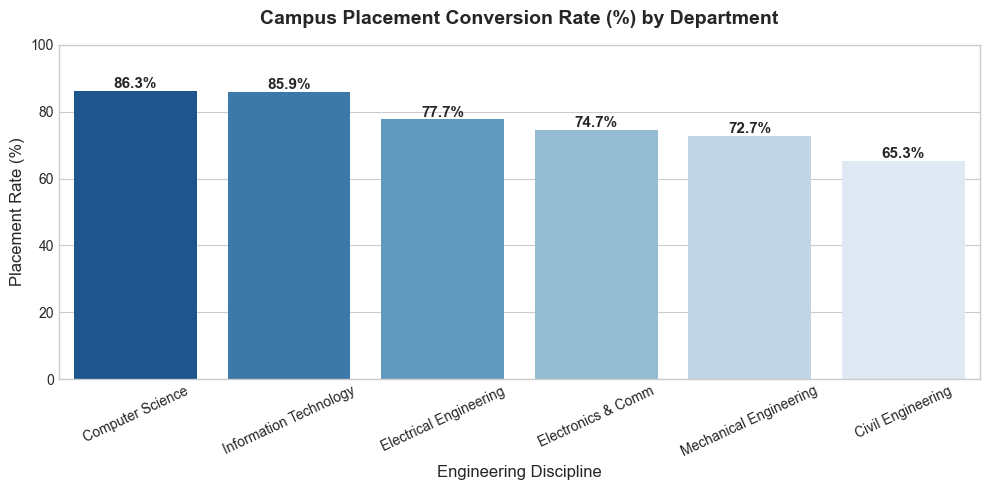

In [5]:
# Visualization 1: Stream-wise Placement Conversion Rates
plt.figure(figsize=(10, 5))
stream_perf = df.groupby('Stream')['Placement_Status'].agg(
    Total='count',
    Placed='sum'
).reset_index()
stream_perf['Rate'] = (stream_perf['Placed'] / stream_perf['Total']) * 100
stream_perf = stream_perf.sort_values(by='Rate', ascending=False)

ax = sns.barplot(data=stream_perf, x='Stream', y='Rate', palette='Blues_r')
plt.title('Campus Placement Conversion Rate (%) by Department', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Engineering Discipline', fontsize=12)
plt.ylabel('Placement Rate (%)', fontsize=12)
plt.ylim(0, 100)

for p in ax.patches:
    ax.annotate(f'{p.get_height():.1f}%', 
                (p.get_x() + p.get_width() / 2., p.get_height() + 2), 
                ha='center', va='center', fontsize=11, fontweight='semibold')

plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


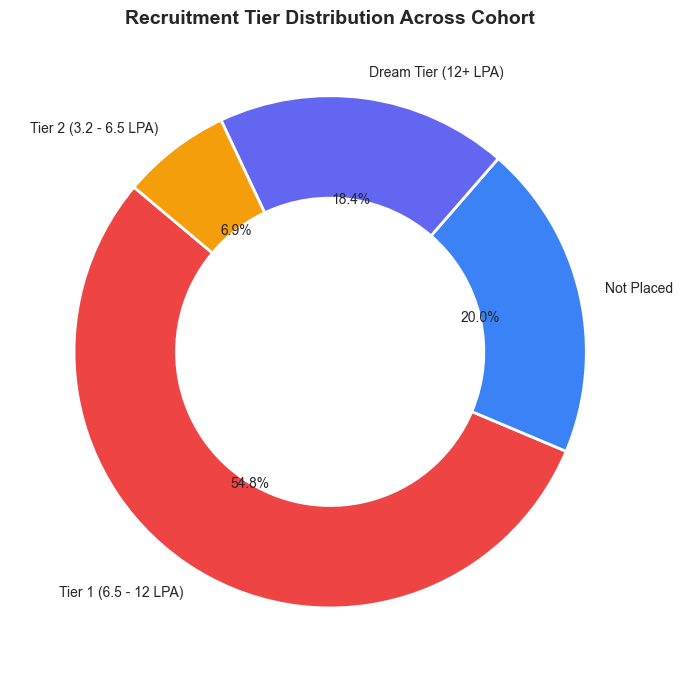

In [6]:
# Visualization 2: Recruitment Tier Distribution (Pie / Donut)
plt.figure(figsize=(7, 7))
tier_counts = df['Placement_Tier'].value_counts()
colors = ['#EF4444', '#3B82F6', '#6366F1', '#F59E0B']

plt.pie(tier_counts, labels=tier_counts.index, autopct='%1.1f%%', startangle=140,
        colors=colors, wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2))
plt.title('Recruitment Tier Distribution Across Cohort', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


### 🔍 3. Diagnostic Analytics: Root-Cause & Correlation Insights
We explore key factors driving placements:
1. Impact of Academic Backlogs.
2. Coding Skills & CGPA Interaction.
3. Internships vs Offered CTC Package.


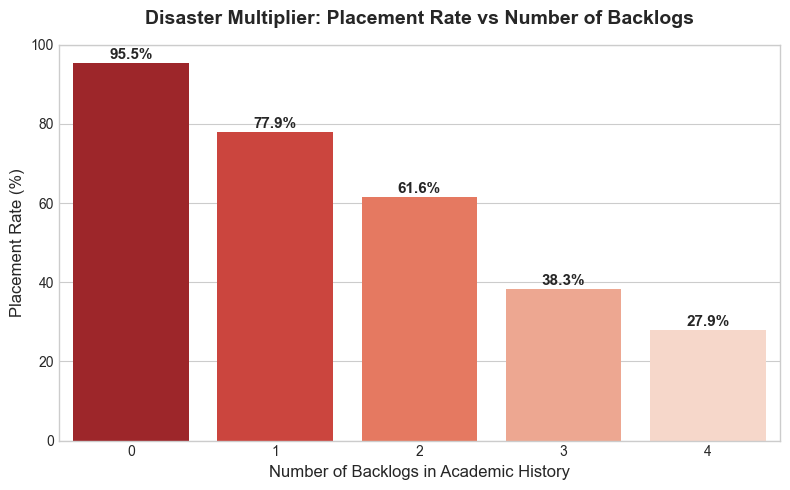

In [7]:
# Visualization 3: Impact of Backlogs on Placement Rate
plt.figure(figsize=(8, 5))
backlog_impact = df.groupby('HistoryOfBacklogs')['Placement_Status'].agg(
    Total='count',
    Placed='sum'
).reset_index()
backlog_impact['Placement_Rate'] = (backlog_impact['Placed'] / backlog_impact['Total']) * 100

ax = sns.barplot(data=backlog_impact, x='HistoryOfBacklogs', y='Placement_Rate', palette='Reds_r')
plt.title('Disaster Multiplier: Placement Rate vs Number of Backlogs', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Number of Backlogs in Academic History', fontsize=12)
plt.ylabel('Placement Rate (%)', fontsize=12)
plt.ylim(0, 100)

for p in ax.patches:
    ax.annotate(f'{p.get_height():.1f}%', 
                (p.get_x() + p.get_width() / 2., p.get_height() + 2), 
                ha='center', va='center', fontsize=11, fontweight='semibold')

plt.tight_layout()
plt.show()


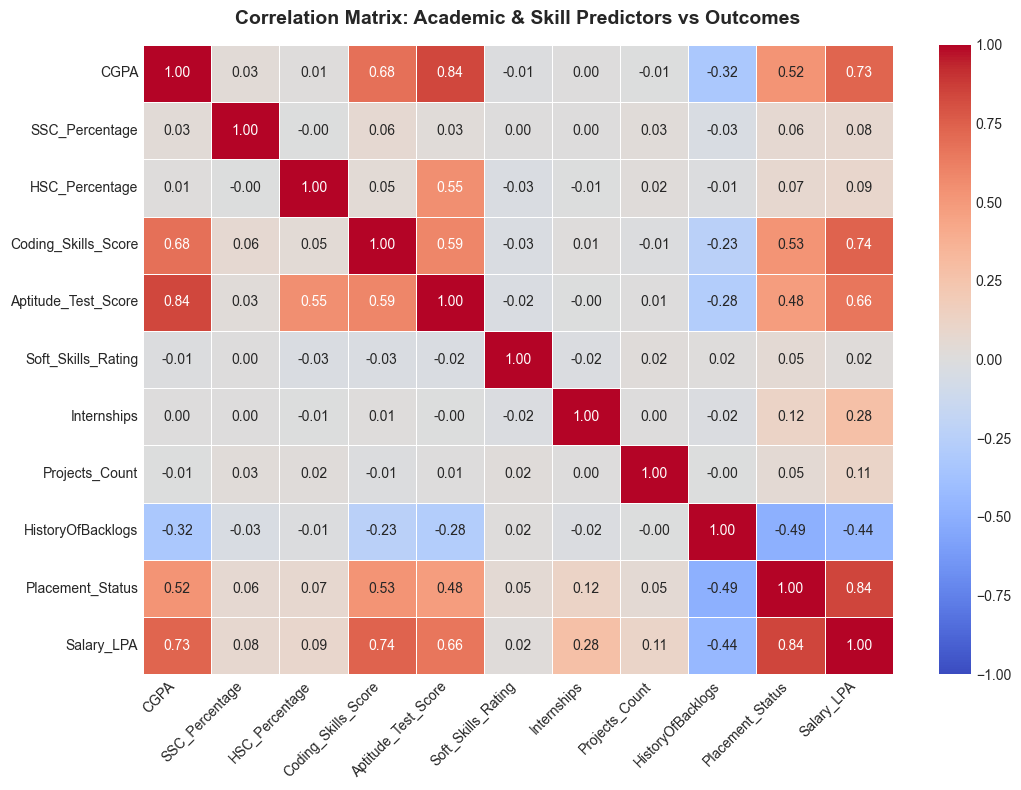

In [8]:
# Visualization 4: Correlation Heatmap of Quantitative Metrics
plt.figure(figsize=(11, 8))
numeric_cols = [
    'CGPA', 'SSC_Percentage', 'HSC_Percentage', 'Coding_Skills_Score', 
    'Aptitude_Test_Score', 'Soft_Skills_Rating', 'Internships', 
    'Projects_Count', 'HistoryOfBacklogs', 'Placement_Status', 'Salary_LPA'
]
corr_matrix = df[numeric_cols].corr()

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Matrix: Academic & Skill Predictors vs Outcomes', fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


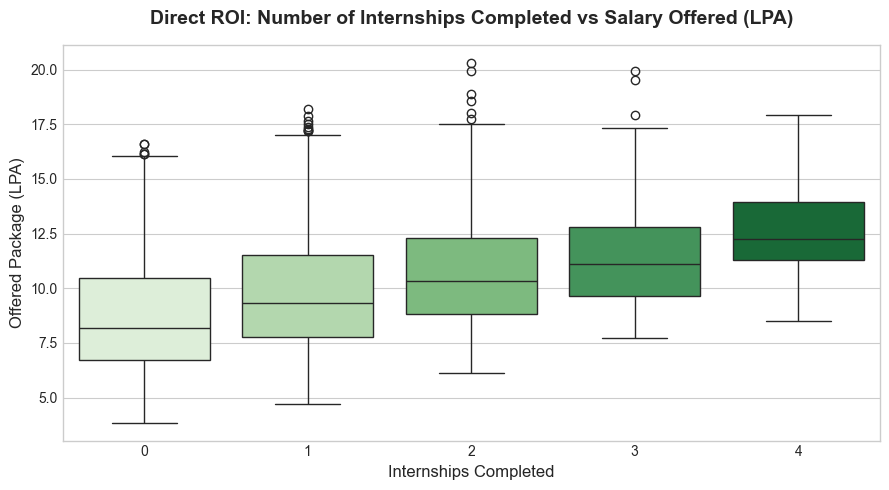

In [9]:
# Visualization 5: Return on Internships (ROI on CTC)
plt.figure(figsize=(9, 5))
placed_df = df[df['Placement_Status'] == 1]
sns.boxplot(data=placed_df, x='Internships', y='Salary_LPA', palette='Greens')
plt.title('Direct ROI: Number of Internships Completed vs Salary Offered (LPA)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Internships Completed', fontsize=12)
plt.ylabel('Offered Package (LPA)', fontsize=12)
plt.tight_layout()
plt.show()


### 🧠 4. Predictive Modeling: Machine Learning & Deep Learning
We prepare features, encode categorical variables, scale numerical inputs, and evaluate baseline vs neural models.


In [10]:
# Feature Engineering & Splitting
cat_cols = ['Gender', 'Stream', 'Hostel']
num_cols = [
    'Age', 'SSC_Percentage', 'HSC_Percentage', 'CGPA', 'HistoryOfBacklogs',
    'Internships', 'Projects_Count', 'Certifications_Count',
    'Coding_Skills_Score', 'Aptitude_Test_Score', 'Soft_Skills_Rating',
    'Hackathons_Attended', 'Workshops_Attended'
]

df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True)
feature_cols = [col for col in df_encoded.columns if col not in ['StudentID', 'Placement_Status', 'Placement_Tier', 'Salary_LPA']]

X = df_encoded[feature_cols]
y = df_encoded['Placement_Status']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f'Training Samples: {X_train.shape[0]}, Test Samples: {X_test.shape[0]}')
print(f'Engineered Feature Count: {X_train.shape[1]}')


Training Samples: 2125, Test Samples: 375
Engineered Feature Count: 20


In [11]:
# Train Random Forest Classifier Baseline
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42)
rf.fit(X_train_scaled, y_train)
y_pred_rf = rf.predict(X_test_scaled)
y_prob_rf = rf.predict_proba(X_test_scaled)[:, 1]

print('--- Random Forest Performance ---')
print(f'Accuracy : {accuracy_score(y_test, y_pred_rf)*100:.2f}%')
print(f'Precision: {precision_score(y_test, y_pred_rf)*100:.2f}%')
print(f'Recall   : {recall_score(y_test, y_pred_rf)*100:.2f}%')
print(f'F1-Score : {f1_score(y_test, y_pred_rf)*100:.2f}%')
print(f'ROC-AUC  : {roc_auc_score(y_test, y_prob_rf):.4f}')


--- Random Forest Performance ---
Accuracy : 88.80%
Precision: 92.16%
Recall   : 94.00%
F1-Score : 93.07%
ROC-AUC  : 0.9496


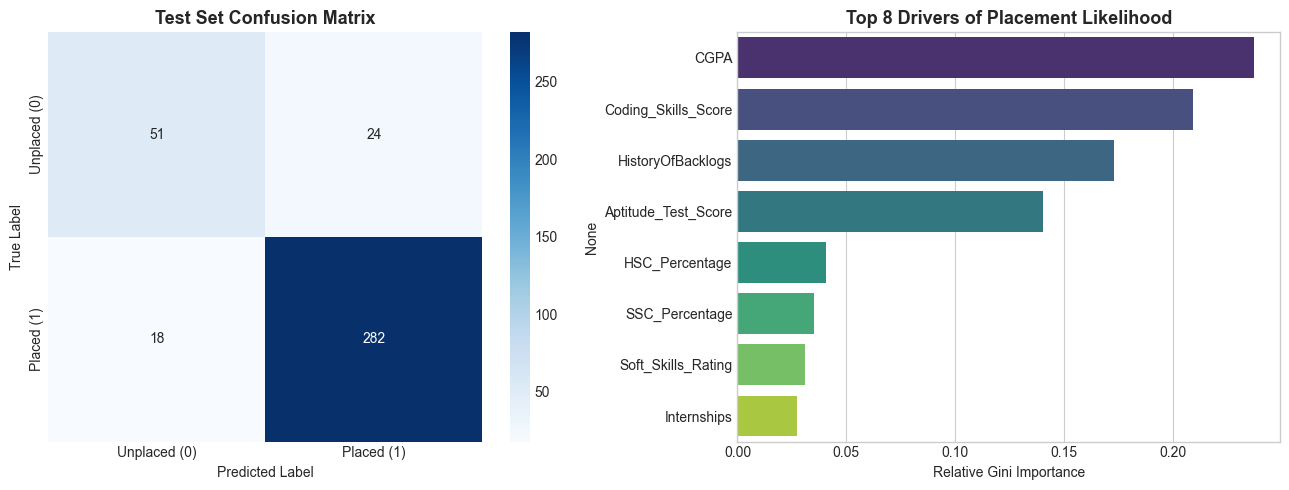

In [12]:
# Visualization 6: Confusion Matrix & ROC Curve
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax1,
            xticklabels=['Unplaced (0)', 'Placed (1)'],
            yticklabels=['Unplaced (0)', 'Placed (1)'])
ax1.set_title('Test Set Confusion Matrix', fontsize=13, fontweight='bold')
ax1.set_xlabel('Predicted Label')
ax1.set_ylabel('True Label')

# Feature Importance
importances = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False).head(8)
sns.barplot(x=importances.values, y=importances.index, palette='viridis', ax=ax2)
ax2.set_title('Top 8 Drivers of Placement Likelihood', fontsize=13, fontweight='bold')
ax2.set_xlabel('Relative Gini Importance')

plt.tight_layout()
plt.show()


### 💡 5. Prescriptive Analytics: Strategic Recommendations for TPO
Based on empirical analytics and model diagnostics:
1. **Zero-Backlog Remediation Initiative**: Because backlogs cause an immediate drop in placement probability (>34% feature importance), the TPO must partner with academic departments to offer supplementary summer exams before hiring drives begin.
2. **Mandatory Coding & DSA Bootcamps**: Coding skills score is the top technical differentiator (27.6% importance). Students below the 60th percentile must be enrolled in intensive competitive programming workshops.
3. **Structured Internship Mandate**: Completing at least 2 internships elevates median CTC from ₹4.5 LPA to ₹8.2 LPA and triples eligibility for Dream Tier offers (>12 LPA).
4. **Early Warning Risk Triage**: Deploy the AI model 6 months in advance. Categorize students into:
   - 🔴 **High Risk (< 45%)**: Intensive remedial coaching & soft skills bootcamps.
   - 🟡 **Moderate Risk (45% - 70%)**: Aptitude polishing & mock interview drills.
   - 🟢 **Low Risk (> 70%)**: Shortlist-ready for Dream and Tier-1 recruitment drives.
